# Боти, смерть, прориви

Порівняння стратегій ботів Sim.Cli (tech 6.1–6.2, критерій етапу 1: «звіти показують різницю між стратегіями ботів»). Дані — `sim run --bot`, один рядок JSONL на забіг; спільний завантажувач — `simruns.py`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from simruns import BOTS, label, load, ranks

RUNS, SEED_FROM = 1000, 1  # per bot; data regenerates by itself when Core, Sim.Cli or content changes
data = load(runs=RUNS, seed_from=SEED_FROM)
runs = data.runs
pd.options.display.float_format = "{:.2f}".format
plt.rcParams["figure.figsize"] = (10, 4)


def named(df, axis=0):
    """Replaces content IDs in the index (axis=0) or columns (axis=1) with Ukrainian names."""
    return df.rename(index=label) if axis == 0 else df.rename(columns=label)


def per_run(long, value, by):
    """Mean of value per run for each bot, counting runs where it never happened as zero."""
    total = long.pivot_table(index=by, columns="bot", values=value, aggfunc="sum", fill_value=0)
    return total.div(runs.groupby("bot").size(), axis=1).reindex(columns=list(BOTS), fill_value=0)


## Підсумок за ботами

Вік смерті в роках, середній досягнутий етап і частки причин кінця забігу.

In [2]:
age = runs.groupby("bot").death_age_years
summary = pd.DataFrame({
    "забігів": runs.groupby("bot").size(),
    "вік смерті, медіана": age.median(),
    "p10": age.quantile(0.1),
    "p90": age.quantile(0.9),
    "етап, середній": runs.groupby("bot").final_stage.mean(),
    "спроб прориву": runs.groupby("bot").breakthrough_attempts.mean(),
}).reindex(list(BOTS))
causes = pd.crosstab(runs.bot, runs.end_cause, normalize="index").reindex(list(BOTS))
summary.join(named(causes, axis=1))

,забігів,"вік смерті, медіана",p10,p90,"етап, середній",спроб прориву,загибель під час прориву,загибель у бою,смерть від старості
bot,,,,,,,,,
cautious,1000,67.52,65.42,69.87,1.91,2.30,0.00,0.00,1.00
fighter,1000,72.81,57.67,75.73,2.44,3.52,0.00,0.10,0.90
random,1000,66.95,20.77,69.60,1.62,1.81,0.03,0.12,0.86


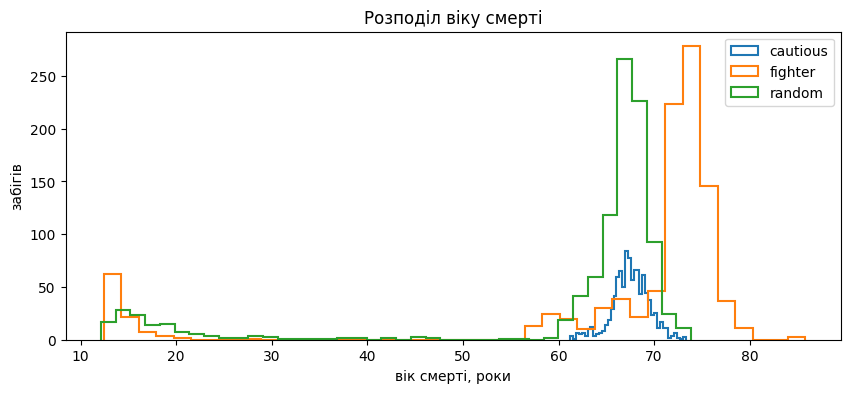

In [3]:
fig, ax = plt.subplots()
for bot in BOTS:
    ax.hist(runs.loc[runs.bot == bot, "death_age_years"], bins=40, histtype="step", linewidth=1.5, label=bot)
ax.set(xlabel="вік смерті, роки", ylabel="забігів", title="Розподіл віку смерті")
ax.legend();

## Досягнутий етап

Частка забігів, що закінчились на кожному етапі ці.

In [4]:
pd.crosstab(runs.bot, runs.final_stage, normalize="index").reindex(list(BOTS))

final_stage,0,1,2,3,4
bot,,,,,
cautious,0.00,0.10,0.91,0.00,0.00
fighter,0.15,0.01,0.10,0.74,0.00
random,0.12,0.14,0.74,0.00,0.00


## Вік на кожному етапі

Вік успішного прориву на етап *N* (тобто з етапу *N − 1*) і частка забігів, що до нього дійшли.

In [5]:
bt = data.breakthroughs
success = bt[bt.result == "success"].assign(stage=lambda d: d.from_stage + 1)
reached = success.groupby(["bot", "stage"]).seed.nunique().div(runs.groupby("bot").size(), level="bot")
stage_age = success.groupby(["bot", "stage"]).age_years.describe(percentiles=[0.1, 0.5, 0.9])
stage_age[["count", "10%", "50%", "90%"]].assign(дійшли=reached)

count   10%   50%   90%  дійшли
bot      stage                                  
cautious 1     1000.00 15.37 16.13 18.94    1.00
         2      905.00 59.00 59.00 59.52    0.91
fighter  1      848.00 14.04 17.17 30.42    0.85
         2      840.00 24.58 29.59 40.55    0.84
         3      744.00 46.43 52.12 61.00    0.74
         4        3.00 72.43 74.17 75.08    0.00
random   1      882.00 18.08 21.88 28.06    0.88
         2      743.00 41.01 51.58 59.55    0.74

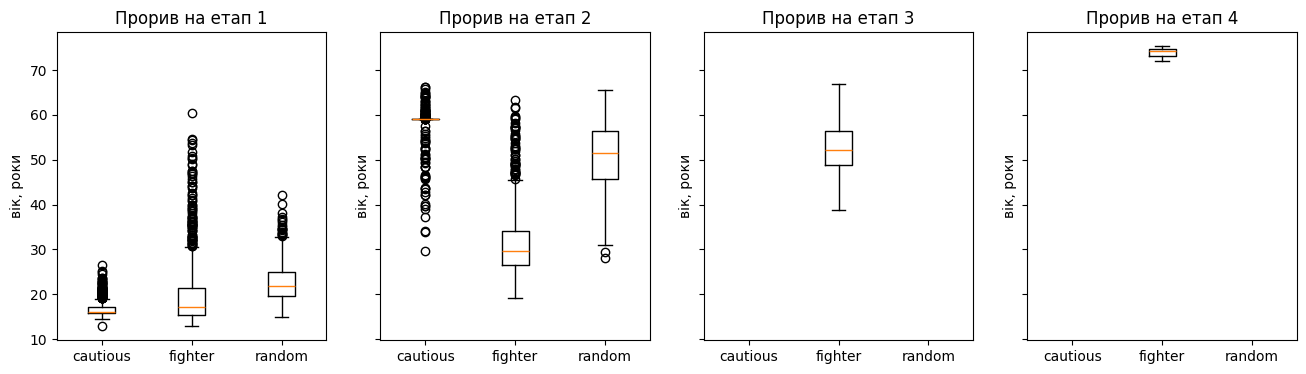

In [6]:
stages = sorted(success.stage.unique())
fig, axes = plt.subplots(1, len(stages), sharey=True, figsize=(4 * len(stages), 4))
for ax, stage in zip(axes if len(stages) > 1 else [axes], stages):
    at = success[success.stage == stage]
    ax.boxplot([at.loc[at.bot == b, "age_years"] for b in BOTS], tick_labels=BOTS)
    ax.set(title=f"Прорив на етап {stage}", ylabel="вік, роки")

## Результати спроб прориву

Частки успіху, провалу й загибелі серед усіх спроб, за етапом, з якого прориваються.

In [7]:
pd.crosstab([bt.bot, bt.from_stage], bt.result, normalize="index")

result               death  failed  success
bot      from_stage                        
cautious 0            0.00    0.00     1.00
         1            0.00    0.30     0.70
fighter  0            0.00    0.03     0.97
         1            0.00    0.39     0.61
         2            0.00    0.41     0.59
         3            0.00    0.75     0.25
random   0            0.02    0.11     0.86
         1            0.00    0.05     0.94

## Якість прориву

Розподіл рангів успішних проривів (від гіршого до кращого) і середній ранг залежно від віку.

In [8]:
order = ranks()
rank_share = pd.crosstab([success.bot, success.stage], success["rank"], normalize="index")
named(rank_share.reindex(columns=[r for r in order if r in rank_share.columns]), axis=1)

rank            Ущербний  Звичайний  Добрий
bot      stage                             
cautious 1          0.00       1.00    0.00
         2          0.98       0.02    0.00
fighter  1          0.25       0.75    0.00
         2          0.95       0.05    0.00
         3          1.00       0.00    0.00
         4          1.00       0.00    0.00
random   1          0.13       0.87    0.00
         2          0.97       0.03    0.00

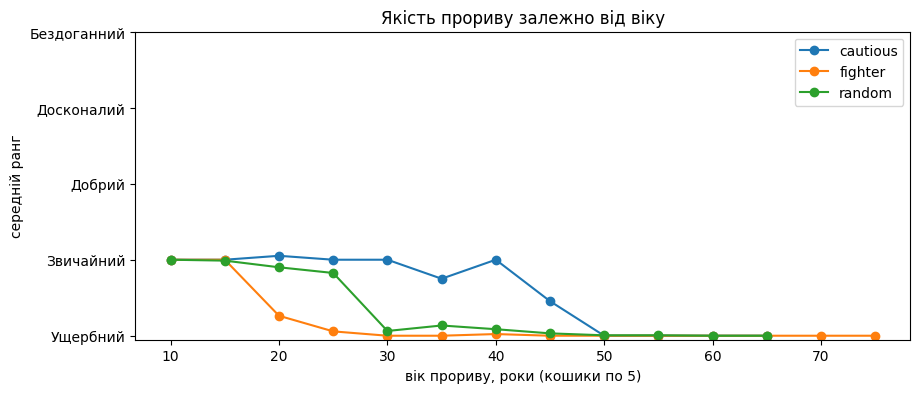

In [9]:
success = success.assign(rank_index=success["rank"].map({r: i for i, r in enumerate(order)}),
                         age_bin=(success.age_years // 5) * 5)
fig, ax = plt.subplots()
for bot in BOTS:
    by_age = success[success.bot == bot].groupby("age_bin").rank_index.mean()
    ax.plot(by_age.index, by_age.values, marker="o", label=bot)
ax.set(xlabel="вік прориву, роки (кошики по 5)", ylabel="середній ранг", title="Якість прориву залежно від віку")
ax.set_yticks(range(len(order)), [label(r) for r in order])
ax.legend();

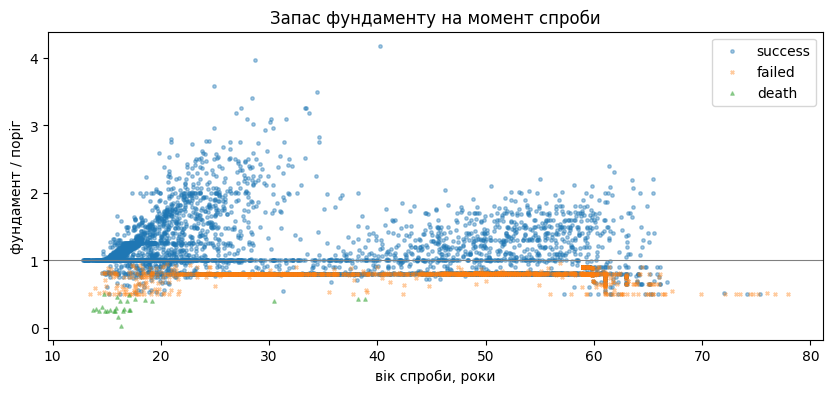

In [10]:
fig, ax = plt.subplots()
for result, marker in [("success", "o"), ("failed", "x"), ("death", "^")]:
    at = bt[bt.result == result]
    ax.scatter(at.age_years, at.foundation / at.threshold, s=6, marker=marker, alpha=0.4, label=result)
ax.axhline(1, color="grey", linewidth=0.8)
ax.set(xlabel="вік спроби, роки", ylabel="фундамент / поріг", title="Запас фундаменту на момент спроби")
ax.legend();

## Розподіл часу

Частка тижнів забігу за заняттями (середнє за ботом); `event` — тижні, які забирають події.

In [11]:
weeks = per_run(data.activity_weeks, "weeks", "activity")
shares = (weeks / runs.groupby("bot").weeks.mean()).T
named(shares, axis=1)

activity,Усамітнення для прориву,event,Розпитування про чутки,Засвоєння,Осягнення,Зцілення,Очищення,Відновлення,Подорож,Відпочинок
bot,,,,,,,,,,
cautious,0.00,0.01,0.00,0.04,0.00,0.00,0.69,0.00,0.26,0.00
fighter,0.01,0.01,0.00,0.06,0.01,0.00,0.10,0.00,0.80,0.00
random,0.00,0.01,0.01,0.02,0.01,0.00,0.21,0.21,0.31,0.20


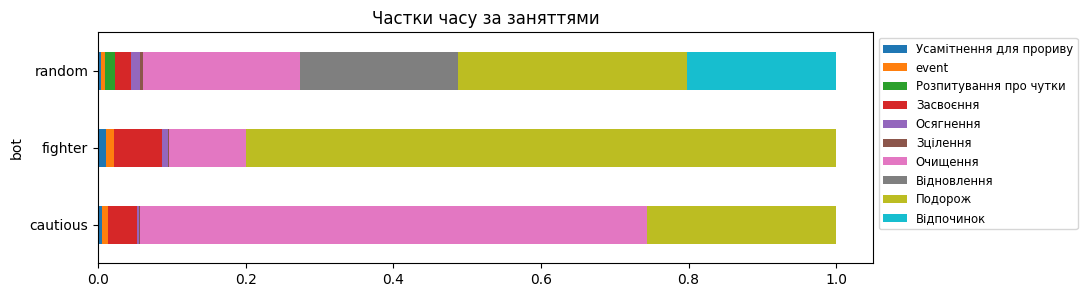

In [12]:
named(shares, axis=1).plot.barh(stacked=True, figsize=(10, 3), title="Частки часу за заняттями")
plt.legend(bbox_to_anchor=(1, 1), loc="upper left", fontsize="small");